# 06 · Classification – predict the AQI category

**Requirements covered:** *Classification: Good / Moderate / Poor / Very Poor / Severe categories* · *classification metrics: accuracy, precision, recall, F1, confusion matrix* · *baseline + 2 ML models*.

The dataset (CPCB) has **six** categories – Good, Satisfactory, Moderate, Poor, Very Poor, Severe (the slide lists five and omits *Satisfactory*; we keep all six because they are what the data contains).

| | |
|---|---|
| Target | `aqi_bucket` (6 ordered classes) |
| Features | the 4 pollutants selected in notebook 04 (PM2.5, PM10, CO, O3). **`AQI` itself is never a feature** – the category is a deterministic function of it (that would be leakage) |
| Baseline | **Logistic Regression** (multinomial, balanced class weights) and a *majority-class* predictor as the floor |
| ML models | **Decision Tree · Random Forest · Gradient Boosting · Neural Net (MLP)** |
| Imbalance | `class_weight='balanced'`, tuning metric **macro-F1**, evaluation with macro-F1 / balanced accuracy / confusion matrix |
| Split | same chronological split as notebook 05 (train < 2019-01-01 ≤ test) |
| Extra | "ordinal" view – a Poor→Very Poor mistake is less bad than Good→Severe – and a comparison with *regress-then-bucket* |

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import classification_report
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

from src import db, config, features, modeling, evaluate
from src.config import LABELS, BUCKET_ORDER, BUCKET_COLORS, TEST_START, LOCKDOWN_START, CORE_CITIES, aqi_to_bucket
from src.viz import set_style, save_fig
set_style(); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

conn = db.get_conn()
df = pd.read_sql_query("SELECT * FROM aqi_features", conn, parse_dates=["date"])
pop = df[(df.in_model_pop == 1)].copy()
sel = json.load(open(config.RESULTS_DIR / "selected_features.json"))
NUM, CAT = sel["numeric"], sel["categorical"]; FEATS = NUM + CAT
FULL_NUM = features.MODEL_POLLUTANTS + features.CALENDAR_FEATURES + features.EVENT_FEATURES; FULL_CAT = features.CATEGORICAL_FEATURES
assert "aqi" not in FEATS and "aqi_bucket" not in FEATS          # leakage guard

train, test = modeling.time_split(pop, TEST_START)
train = train.sort_values("date").reset_index(drop=True); test = test.sort_values(["date", "city"]).reset_index(drop=True)
lock = pd.Timestamp(LOCKDOWN_START)
print("features:", [LABELS[f] for f in FEATS], f"| train {len(train):,} | test {len(test):,}")

features: ['PM2.5', 'PM10', 'CO', 'O3'] | train 12,541 | test 10,959


### Class distribution: train vs test

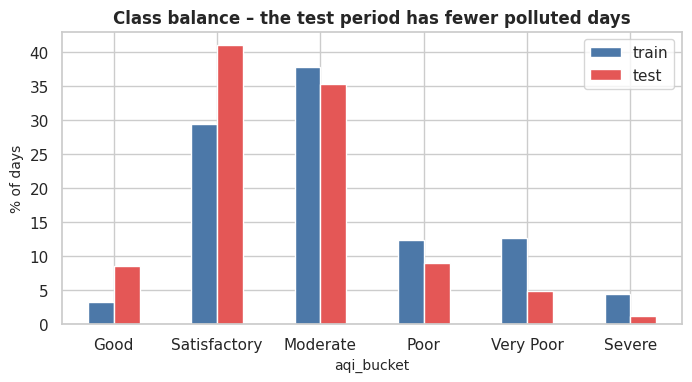

aqi_bucket,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
train,3.2,29.4,37.8,12.4,12.6,4.5
test,8.6,41.0,35.3,9.0,4.9,1.2


In [2]:
dist = pd.DataFrame({"train": train.aqi_bucket.value_counts(normalize=True), "test": test.aqi_bucket.value_counts(normalize=True)}).reindex(BUCKET_ORDER).mul(100).round(1)
fig, ax = plt.subplots(figsize=(8, 3.8)); dist.plot.bar(ax=ax, color=["#4c78a8", "#e45756"], rot=0); ax.set_ylabel("% of days"); ax.set_title("Class balance – the test period has fewer polluted days")
save_fig("06_class_distribution"); plt.show(); dist.T

## 1 · Train and tune (metric: macro-F1, time-series CV)

In [3]:
catalog = modeling.classification_catalog()
fitted, info = {}, {}
cv = TimeSeriesSplit(n_splits=3)
for name, spec in catalog.items():
    pipe, i = modeling.fit_model(name, spec, NUM, CAT, train[FEATS], train["aqi_bucket"], scoring="f1_macro", n_iter=5)
    if not np.isfinite(i["cv_score"]):
        i["cv_score"] = cross_val_score(clone(pipe), train[FEATS], train["aqi_bucket"], cv=cv, scoring="f1_macro").mean()
    fitted[name], info[name] = pipe, i

  Majority class (dummy)       fitted in    0.0s   best params: -
  Logistic Regression          fitted in    0.1s   best params: -
  Decision Tree                fitted in    0.9s   best params: {'min_samples_leaf': 10, 'max_depth': 10}
  Random Forest                fitted in   20.5s   best params: {'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': 12}
  Gradient Boosting (HistGB)   fitted in   20.7s   best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.1, 'l2_regularization': 1.0}
  Neural Net (MLP)             fitted in    8.5s   best params: -


## 2 · Results

In [4]:
def eval_sets(pipe):
    out = {}
    for label, d in [("train", train), ("test", test), ("test_pre_lockdown", test[test.date < lock]), ("test_lockdown", test[test.date >= lock])]:
        out[label] = evaluate.classification_metrics(d["aqi_bucket"], pipe.predict(d[FEATS]))
    return out
res, log_rows = {}, []
for n, p in fitted.items():
    res[n] = eval_sets(p)
    for es, m in res[n].items(): log_rows += evaluate.to_rows(n, "selected(4)", es, m)

table = pd.DataFrame({n: {"CV macro-F1 (train)": info[n]["cv_score"], "train accuracy": r["train"]["accuracy"], "test accuracy": r["test"]["accuracy"],
                          "test balanced acc.": r["test"]["balanced_accuracy"], "test precision (macro)": r["test"]["precision_macro"],
                          "test recall (macro)": r["test"]["recall_macro"], "test F1 (macro)": r["test"]["f1_macro"], "test F1 (weighted)": r["test"]["f1_weighted"],
                          "within ±1 class": r["test"]["within_1_class"]} for n, r in res.items()}).T.sort_values("test F1 (macro)", ascending=False).round(3)
table

,CV macro-F1 (train),train accuracy,test accuracy,test balanced acc.,test precision (macro),test recall (macro),test F1 (macro),test F1 (weighted),within ±1 class
Random Forest,0.676,0.841,0.785,0.769,0.747,0.769,0.756,0.787,0.997
Neural Net (MLP),0.636,0.778,0.785,0.730,0.767,0.730,0.746,0.783,0.997
Gradient Boosting (HistGB),0.650,0.786,0.761,0.782,0.708,0.782,0.733,0.765,0.996
Decision Tree,0.599,0.765,0.726,0.759,0.673,0.759,0.703,0.732,0.991
Logistic Regression,0.557,0.641,0.602,0.708,0.602,0.708,0.608,0.621,0.973
Majority class (dummy),0.087,0.378,0.353,0.167,0.059,0.167,0.087,0.184,0.853


best model by time-series CV (no test data used): Random Forest


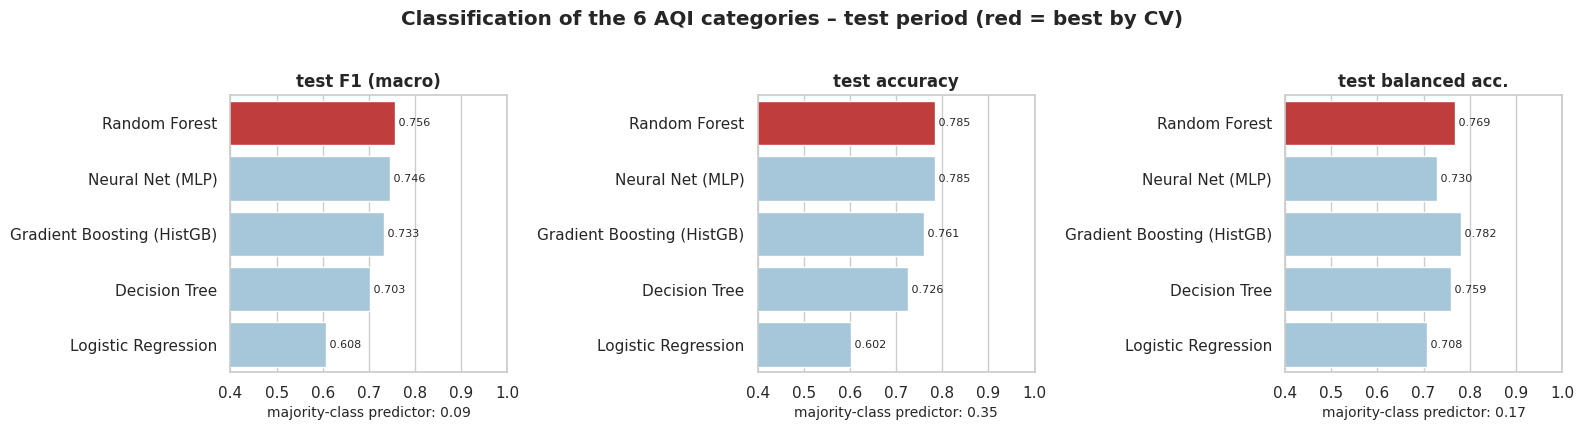

In [5]:
best_name = max((n for n in info if n != "Majority class (dummy)"), key=lambda n: info[n]["cv_score"])     # chosen with CV on train only
print("best model by time-series CV (no test data used):", best_name)
best, base = fitted[best_name], fitted["Logistic Regression"]
order = [n for n in table.index if n != "Majority class (dummy)"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, ["test F1 (macro)", "test accuracy", "test balanced acc."]):
    sns.barplot(x=table.loc[order, col], y=order, order=order, ax=ax, palette=["#d62728" if n == best_name else "#9ecae1" for n in order]); ax.set_ylabel(""); ax.set_title(col); ax.set_xlim(0.4, 1.0)
    ax.set_xlabel(f"majority-class predictor: {table.loc['Majority class (dummy)', col]:.2f}")
    for i, n in enumerate(order): ax.text(table.loc[n, col], i, f" {table.loc[n, col]:.3f}", va="center", fontsize=8)
plt.suptitle("Classification of the 6 AQI categories – test period (red = best by CV)", y=1.02, fontweight="bold")
plt.tight_layout(); save_fig("06_model_comparison"); plt.show()

*Why macro-F1?* Accuracy rewards predicting the common classes; **macro-F1** averages the F1 of all six classes equally, so rare classes (Good, Severe) count as much as Moderate.

In [6]:
pd.DataFrame({n: i["best_params"] for n, i in info.items() if i["best_params"]}).T.fillna("-")

,min_samples_leaf,max_depth,max_features,max_leaf_nodes,learning_rate,l2_regularization
Decision Tree,10.0,10.0,-,-,-,-
Random Forest,3,12,sqrt,-,-,-
Gradient Boosting (HistGB),20.0,-,-,15.0,0.1,1.0


## 3 · Confusion matrices – baseline vs best model

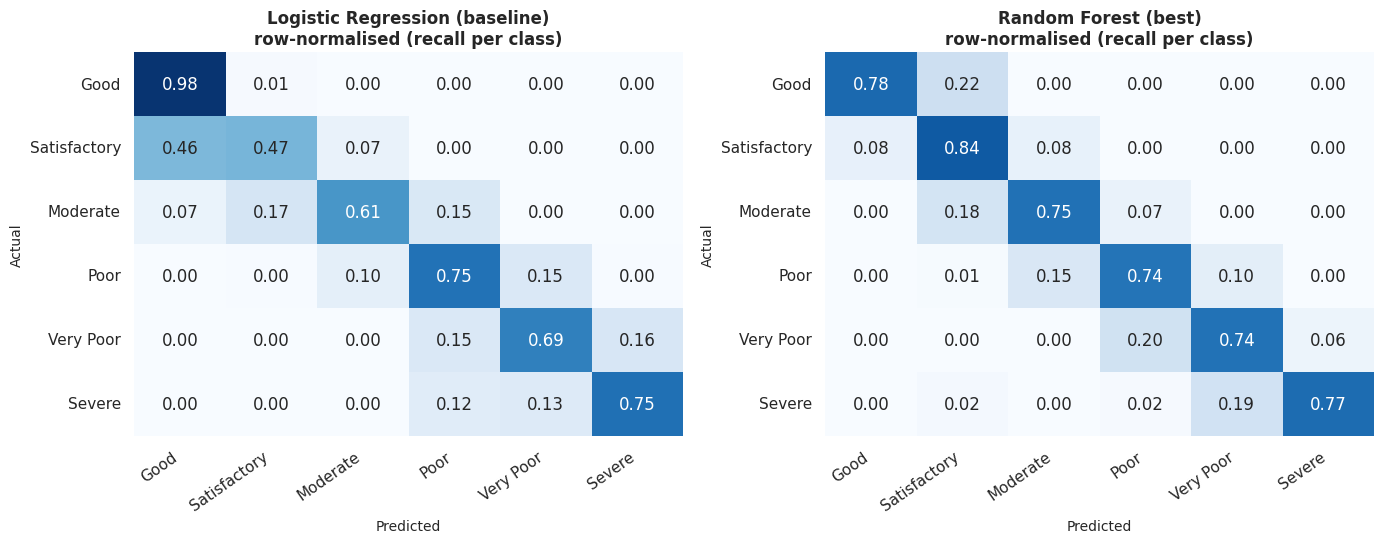

predicted,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
actual,,,,,,
Good,734,203,3,1,0,0
Satisfactory,376,3760,356,3,0,0
Moderate,7,697,2891,274,3,0
Poor,0,8,151,723,100,1
Very Poor,0,0,1,107,400,30
Severe,0,3,0,2,25,100


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, (nm, p) in zip(axes, [("Logistic Regression (baseline)", base), (f"{best_name} (best)", best)]):
    evaluate.plot_confusion(test["aqi_bucket"], p.predict(test[FEATS]), f"{nm}\nrow-normalised (recall per class)", ax=ax)
plt.tight_layout(); save_fig("06_confusion_matrices"); plt.show()
cm_counts = pd.crosstab(test["aqi_bucket"].rename("actual"), pd.Series(best.predict(test[FEATS]), name="predicted")).reindex(index=BUCKET_ORDER, columns=BUCKET_ORDER, fill_value=0); cm_counts

Per-class report – Random Forest


,precision,recall,f1-score,support
Good,0.657,0.780,0.713,941.000
Satisfactory,0.805,0.836,0.820,4495.000
Moderate,0.850,0.747,0.795,3872.000
Poor,0.651,0.736,0.691,983.000
Very Poor,0.758,0.743,0.750,538.000
Severe,0.763,0.769,0.766,130.000
accuracy,0.785,0.785,0.785,0.785
macro avg,0.747,0.769,0.756,10959.000
weighted avg,0.792,0.785,0.787,10959.000


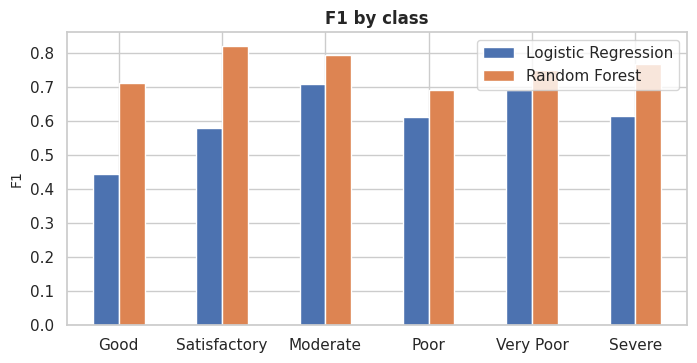

In [8]:
rep = pd.DataFrame(classification_report(test["aqi_bucket"], best.predict(test[FEATS]), labels=BUCKET_ORDER, output_dict=True, zero_division=0)).T.round(3)
rep_b = pd.DataFrame(classification_report(test["aqi_bucket"], base.predict(test[FEATS]), labels=BUCKET_ORDER, output_dict=True, zero_division=0)).T.round(3)
print(f"Per-class report – {best_name}"); display(rep)
f1 = pd.DataFrame({"Logistic Regression": rep_b.loc[BUCKET_ORDER, "f1-score"], best_name: rep.loc[BUCKET_ORDER, "f1-score"]})
ax = f1.plot.bar(figsize=(8, 3.8), rot=0); ax.set_ylabel("F1"); ax.set_title("F1 by class"); save_fig("06_f1_by_class"); plt.show()

## 4 · How wrong are the mistakes? (ordinal view)
The categories are ordered. Predicting *Poor* when the truth is *Very Poor* (distance 1) is much less severe than predicting *Good* when it is *Severe* (distance 5).

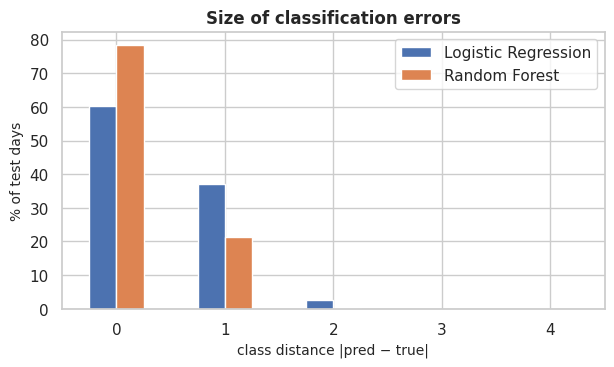

,Logistic Regression,Random Forest
class distance |pred − true|,,
0,60.2,78.5
1,37.2,21.2
2,2.6,0.3
3,0.0,0.0
4,0.0,0.0


In [9]:
order_ix = {b: i for i, b in enumerate(BUCKET_ORDER)}
dist_err = pd.DataFrame({m: (pd.Series(p.predict(test[FEATS])).map(order_ix) - test["aqi_bucket"].map(order_ix)).abs().value_counts(normalize=True).sort_index().mul(100)
                         for m, p in [("Logistic Regression", base), (best_name, best)]}).fillna(0).round(1)
dist_err.index.name = "class distance |pred − true|"
ax = dist_err.plot.bar(figsize=(7, 3.6), rot=0); ax.set_ylabel("% of test days"); ax.set_title("Size of classification errors"); save_fig("06_ordinal_error"); plt.show(); dist_err

## 5 · Direct classifier vs "regress, then bucket"
Alternative: predict the numeric AQI with the regression model (notebook 05) and convert it to a category with the CPCB thresholds.

In [10]:
reg = pd.read_csv(config.RESULTS_DIR / "regression_same_day_predictions.csv", parse_dates=["date"])
m = test[["city", "date", "aqi_bucket"]].merge(reg, on=["city", "date"], how="left")
rows = []
for col in ["Linear Regression", "Random Forest", "Gradient Boosting (HistGB)", "Neural Net (MLP)"]:
    pred = m[col].map(aqi_to_bucket); rows.append({"approach": f"regress ({col}) → bucket", **evaluate.classification_metrics(m["aqi_bucket"], pred)})
rows.append({"approach": f"direct classifier ({best_name})", **evaluate.classification_metrics(test["aqi_bucket"], best.predict(test[FEATS]))})
rows.append({"approach": "direct classifier (Logistic Regression)", **evaluate.classification_metrics(test["aqi_bucket"], base.predict(test[FEATS]))})
rb = pd.DataFrame(rows).set_index("approach")[["accuracy", "balanced_accuracy", "f1_macro", "within_1_class"]].round(3); rb

,accuracy,balanced_accuracy,f1_macro,within_1_class
approach,,,,
regress (Linear Regression) → bucket,0.699,0.582,0.614,0.996
regress (Random Forest) → bucket,0.780,0.692,0.718,0.997
regress (Gradient Boosting (HistGB)) → bucket,0.773,0.683,0.706,0.998
regress (Neural Net (MLP)) → bucket,0.774,0.710,0.728,0.998
direct classifier (Random Forest),0.785,0.769,0.756,0.997
direct classifier (Logistic Regression),0.602,0.708,0.608,0.973


## 6 · Robustness

In [11]:
# (a) 4 selected features vs all 23 – same hyper-parameters
rows = []
for name in ["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting (HistGB)"]:
    spec = catalog[name]; est = clone(spec["est"]).set_params(**info[name]["best_params"])
    p = modeling.make_pipeline(est, FULL_NUM, FULL_CAT, spec["kind"]).fit(train[FULL_NUM + FULL_CAT], train["aqi_bucket"])
    mf = evaluate.classification_metrics(test["aqi_bucket"], p.predict(test[FULL_NUM + FULL_CAT]))
    rows.append({"model": name, "macro-F1 (4 features)": res[name]["test"]["f1_macro"], "macro-F1 (23 features)": mf["f1_macro"], "accuracy (4)": res[name]["test"]["accuracy"], "accuracy (23)": mf["accuracy"]})
    log_rows += evaluate.to_rows(name, "full(23)", "test", mf)
pd.DataFrame(rows).round(3)

,model,macro-F1 (4 features),macro-F1 (23 features),accuracy (4),accuracy (23)
0,Logistic Regression,0.608,0.628,0.602,0.656
1,Decision Tree,0.703,0.685,0.726,0.719
2,Random Forest,0.756,0.745,0.785,0.780
3,Gradient Boosting (HistGB),0.733,0.748,0.761,0.777


In [12]:
# (b) does class weighting matter?  Random Forest with and without balanced weights
est = clone(catalog["Random Forest"]["est"]).set_params(**info["Random Forest"]["best_params"])
rows = []
for cw in ["balanced_subsample", None]:
    p = modeling.make_pipeline(clone(est).set_params(class_weight=cw), NUM, CAT, "tree").fit(train[FEATS], train["aqi_bucket"])
    pr = p.predict(test[FEATS]); r = classification_report(test["aqi_bucket"], pr, labels=BUCKET_ORDER, output_dict=True, zero_division=0)
    rows.append({"class_weight": str(cw), "accuracy": (pr == test["aqi_bucket"]).mean(), "macro-F1": r["macro avg"]["f1-score"],
                 "recall Good": r["Good"]["recall"], "recall Severe": r["Severe"]["recall"], "recall Very Poor": r["Very Poor"]["recall"]})
pd.DataFrame(rows).round(3)

,class_weight,accuracy,macro-F1,recall Good,recall Severe,recall Very Poor
0,balanced_subsample,0.785,0.756,0.780,0.769,0.743
1,None,0.792,0.750,0.554,0.746,0.753


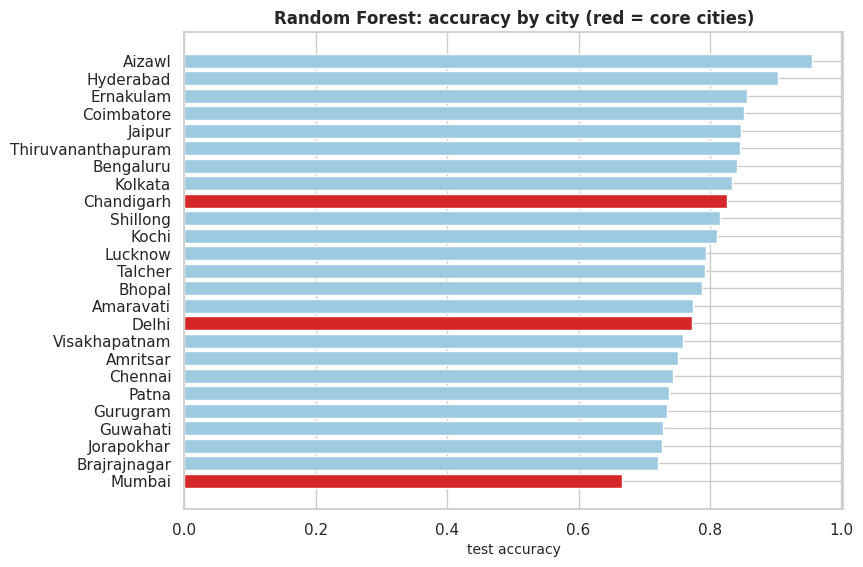

,n,accuracy,within_1_class
city,,,
Delhi,548.0,0.772,0.998
Chandigarh,299.0,0.826,1.000
Mumbai,548.0,0.666,1.000


In [13]:
# (c) per-city performance of the best model, with the three core cities highlighted
tp = test.assign(pred=best.predict(test[FEATS]))
cityres = tp.groupby("city").apply(lambda g: pd.Series({"n": len(g), "accuracy": (g.pred == g.aqi_bucket).mean(),
        "within_1_class": ((g.pred.map(order_ix) - g.aqi_bucket.map(order_ix)).abs() <= 1).mean()})).sort_values("accuracy").round(3)
fig, ax = plt.subplots(figsize=(8.5, 6.2)); ax.barh(cityres.index, cityres.accuracy, color=["#d62728" if c in CORE_CITIES else "#9ecae1" for c in cityres.index]); ax.set_xlabel("test accuracy"); ax.set_title(f"{best_name}: accuracy by city (red = core cities)")
save_fig("06_accuracy_by_city"); plt.show(); cityres.loc[[c for c in CORE_CITIES if c in cityres.index]]

In [14]:
# (d) leakage sanity check: shuffled labels should give ~chance performance
rng = np.random.default_rng(0)
est = clone(catalog["Gradient Boosting (HistGB)"]["est"]).set_params(**info["Gradient Boosting (HistGB)"]["best_params"])
p = modeling.make_pipeline(est, NUM, CAT, "tree").fit(train[FEATS], rng.permutation(train["aqi_bucket"].values))
print("macro-F1 of a model trained on shuffled labels:", round(evaluate.classification_metrics(test["aqi_bucket"], p.predict(test[FEATS]))["f1_macro"], 3), "(chance level ≈ 0.1-0.2)")

macro-F1 of a model trained on shuffled labels: 0.118 (chance level ≈ 0.1-0.2)


## 7 · Save

In [15]:
table.to_csv(config.RESULTS_DIR / "classification_same_day_results.csv"); rep.to_csv(config.RESULTS_DIR / "classification_best_per_class.csv"); cityres.to_csv(config.RESULTS_DIR / "classification_by_city.csv")
rb.to_csv(config.RESULTS_DIR / "classification_regress_then_bucket.csv")
json.dump({"best_by_cv": best_name, "best_params": {n: {k: (None if v is None else (float(v) if isinstance(v, np.floating) else (int(v) if isinstance(v, np.integer) else v))) for k, v in i["best_params"].items()} for n, i in info.items()}},
          open(config.RESULTS_DIR / "classification_best_params.json", "w"), indent=2)
db.log_results(log_rows, "classification_same_day", conn); conn.close()
for nm in dict.fromkeys(["Logistic Regression", best_name]):
    path = config.MODELS_DIR / f"classification_{nm.split(' (')[0].lower().replace(' ', '_')}.joblib"; joblib.dump(fitted[nm], path, compress=3)
    print(f"saved {path.relative_to(ROOT)}  ({path.stat().st_size / 1e6:.2f} MB)")

saved models/classification_logistic_regression.joblib  (0.00 MB)
saved models/classification_random_forest.joblib  (5.19 MB)


## 8 · Conclusions – classification

| Model | Test accuracy | Balanced acc. | Precision (macro) | Recall (macro) | **F1 (macro)** |
|---|---|---|---|---|---|
| Majority class (floor) | 0.353 | 0.167 | 0.059 | 0.167 | 0.087 |
| **Logistic Regression (baseline)** | 0.602 | 0.708 | 0.602 | 0.708 | 0.608 |
| Decision Tree | 0.726 | 0.759 | 0.673 | 0.759 | 0.703 |
| Gradient Boosting (HistGB) | 0.761 | 0.782 | 0.708 | 0.782 | 0.733 |
| Neural Net (MLP) | 0.785 | 0.730 | 0.767 | 0.730 | 0.746 |
| **Random Forest (best by CV)** | **0.785** | 0.769 | 0.747 | 0.769 | **0.756** |

1. **All ML models clearly beat the baseline** (macro-F1 0.70–0.76 vs 0.61) and the majority-class floor (0.09). Random Forest is best by time-series CV *and* on the test period.
2. **Mistakes are almost always adjacent categories:** Random Forest is exactly right on 78.5 % of days, off by one class on 21.2 %, by two on 0.3 %, never more. **99.7 % of predictions are within ±1 class** (baseline: 97.3 %). The accuracy ceiling of ~79 % is natural: a category is a *threshold* of a continuous AQI, and with a regression error of ≈ 16 AQI points a day with AQI 98 vs 102 flips between Satisfactory and Moderate.
3. **Hardest classes:** *Poor* (F1 0.69) and *Good* (0.71); the rare *Severe* class is predicted well (F1 0.77, recall 0.77) thanks to class weighting.
4. **Class weighting works as intended:** without it, recall for *Good* falls from 0.78 to 0.55 for a marginal accuracy gain (0.792 vs 0.785) – a typical imbalance trap.
5. **Direct classification beats "regress, then bucket"** on balanced accuracy (0.77 vs 0.69–0.71) and macro-F1 (0.756 vs 0.72–0.73), although plain accuracy is the same (≈ 0.78): the direct models learn the rare classes better.
6. **City differences:** Chandigarh 82.6 % accuracy, Delhi 77.2 %, Mumbai only 66.6 % – Mumbai's AQI hovers around the 100 boundary between *Satisfactory* and *Moderate*, so small errors flip the class (still 100 % within ±1 class).
7. **Distribution shift:** the test period is cleaner than the training period (Good 8.6 % vs 3.2 %, Severe 1.2 % vs 4.5 %); the models still transfer well.
8. **Feature reduction holds:** 4 vs 23 features gives similar macro-F1 for the tree models (RF 0.756 vs 0.745, HistGB 0.733 vs 0.748); only the linear baseline profits from more features (0.608 → 0.628), because calendar/city information helps a weak model.
9. **No leakage:** a model trained on shuffled labels reaches only macro-F1 = 0.12; `AQI` is never a feature (asserted in the code).

➡ Next: `07_city_comparison_and_nextday.ipynb` – comparison of Delhi, Chandigarh, Mumbai and nearby cities, and the real forecasting task (tomorrow's AQI).